<a href="https://colab.research.google.com/github/elyes098a/elyesetude/blob/main/Depistage_Risque_Cardiovasculaire_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

🏥 Génération du dossier médical de la cohorte...
✅ Cohorte prête : 600 dossiers analysables.
📊 Répartition : 25.7% de patients à risque.

🧠 Entraînement de l'algorithme de dépistage...

📋 RAPPORT DE PERFORMANCE CLINIQUE
Sensibilité (Capacité à détecter les vrais malades) : 65.8%

                  precision    recall  f1-score   support

    Patient Sain       0.89      0.96      0.93       112
Risque Cardiaque       0.86      0.66      0.75        38

        accuracy                           0.89       150
       macro avg       0.88      0.81      0.84       150
    weighted avg       0.88      0.89      0.88       150



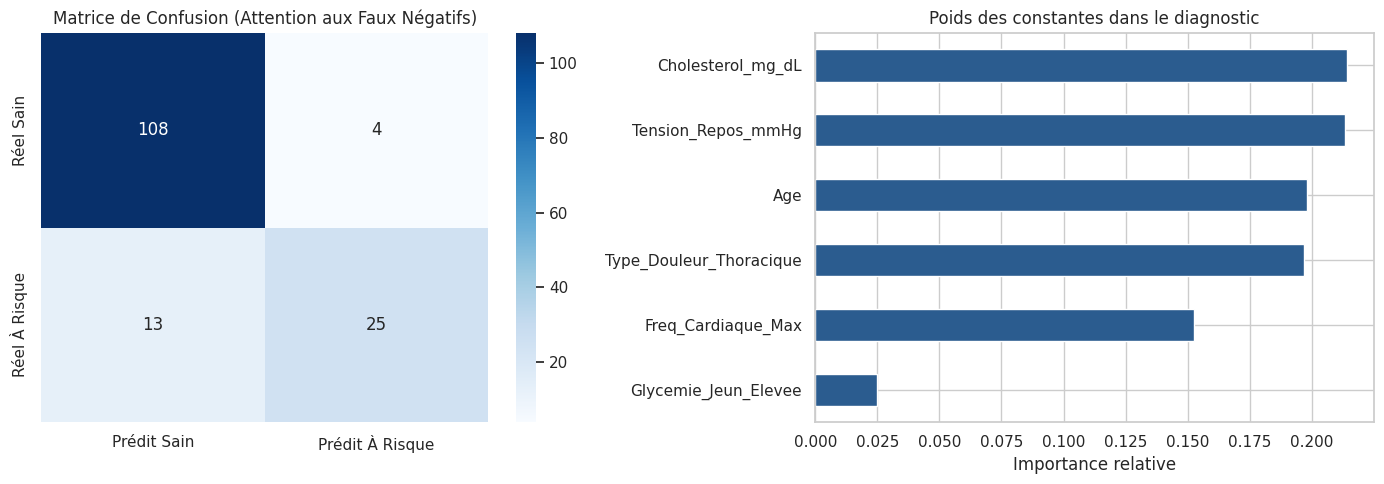


🩺 --- RÉSULTAT DE LA CONSULTATION ASSISTÉE ---
Profil : 64 ans | Tension : 155 mmHg | Cholestérol : 265 mg/dL
Probabilité estimée de pathologie cardiaque : 95.9%
⚠️ ALERTE : Risque élevé détecté. Bilan cardiologique approfondi recommandé.


In [1]:
# ==============================================================================
# PROJET : Aide au dépistage du risque cardiovasculaire par Machine Learning
# ENVIRONNEMENT : Prêt pour Google Colab (aucun fichier externe requis)
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, recall_score

# Configuration esthétique des graphiques
sns.set_theme(style="whitegrid")
np.random.seed(42)

# ------------------------------------------------------------------------------
# 1. CRÉATION D'UN JEU DE DONNÉES CLINIQUES (COHORTE DE 600 PATIENTS)
# ------------------------------------------------------------------------------
print("🏥 Génération du dossier médical de la cohorte...")

n_patients = 600

# Variables physiologiques réalistes
age = np.random.randint(30, 80, size=n_patients)
tension_repos = np.random.normal(130, 18, size=n_patients).astype(int)  # mmHg
cholesterol = np.random.normal(235, 45, size=n_patients).astype(int)    # mg/dL
freq_cardiaque_max = np.random.normal(150, 22, size=n_patients).astype(int)
glycemie_jeun = np.random.choice([0, 1], size=n_patients, p=[0.82, 0.18]) # 1 si > 120 mg/dL
douleur_thoracique = np.random.choice([0, 1, 2, 3], size=n_patients, p=[0.45, 0.25, 0.20, 0.10])

# Calcul d'un score de risque médical sous-jacent pour générer le diagnostic réel
score_risque = (
    (age > 55) * 1.5 +
    (tension_repos > 140) * 1.8 +
    (cholesterol > 250) * 1.2 +
    (freq_cardiaque_max < 130) * 1.4 +
    (glycemie_jeun == 1) * 1.1 +
    (douleur_thoracique >= 2) * 2.2 +
    np.random.normal(0, 1.2, size=n_patients) # Variabilité biologique naturelle
)

# Diagnostic : 1 = Pathologie détectée, 0 = Sain
diagnostic = (score_risque > 4.2).astype(int)

dossier_patients = pd.DataFrame({
    'Age': age,
    'Tension_Repos_mmHg': tension_repos,
    'Cholesterol_mg_dL': cholesterol,
    'Freq_Cardiaque_Max': freq_cardiaque_max,
    'Glycemie_Jeun_Elevee': glycemie_jeun,
    'Type_Douleur_Thoracique': douleur_thoracique,
    'Pathologie_Cardiaque': diagnostic
})

print(f"✅ Cohorte prête : {len(dossier_patients)} dossiers analysables.")
print(f"📊 Répartition : {dossier_patients['Pathologie_Cardiaque'].mean()*100:.1f}% de patients à risque.\n")

# ------------------------------------------------------------------------------
# 2. PRÉPARATION ET SÉPARATION DES DONNÉES
# ------------------------------------------------------------------------------
# On sépare les symptômes/constantes (X) du diagnostic final (y)
X = dossier_patients.drop('Pathologie_Cardiaque', axis=1)
y = dossier_patients['Pathologie_Cardiaque']

# Stratification pour garder exactement la même proportion de malades dans chaque groupe
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Normalisation (bonne pratique même si Random Forest y est peu sensible)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------------------------
# 3. ENTRAÎNEMENT DU MODÈLE (FORÊT ALÉATOIRE)
# ------------------------------------------------------------------------------
print("🧠 Entraînement de l'algorithme de dépistage...")

# class_weight='balanced' évite que le modèle néglige les cas minoritaires
modele_medical = RandomForestClassifier(
    n_estimators=150,
    max_depth=6,           # Limite la profondeur pour éviter le surapprentissage (overfitting)
    class_weight='balanced',
    random_state=42
)
modele_medical.fit(X_train_scaled, y_train)

# ------------------------------------------------------------------------------
# 4. ÉVALUATION CLINIQUE DU MODÈLE
# ------------------------------------------------------------------------------
predictions = modele_medical.predict(X_test_scaled)

# En médecine, la Sensibilité (Recall) est vitale : on veut rater le moins de malades possible
sensibilite = recall_score(y_test, predictions)

print("\n" + "="*50)
print("📋 RAPPORT DE PERFORMANCE CLINIQUE")
print("="*50)
print(f"Sensibilité (Capacité à détecter les vrais malades) : {sensibilite*100:.1f}%\n")
print(classification_report(y_test, predictions, target_names=['Patient Sain', 'Risque Cardiaque']))

# Visualisation : Matrice de confusion et Importance des facteurs cliniques
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : Matrice de confusion
cm = confusion_matrix(y_test, predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Prédit Sain', 'Prédit À Risque'],
            yticklabels=['Réel Sain', 'Réel À Risque'])
axes[0].set_title("Matrice de Confusion (Attention aux Faux Négatifs)")

# Graphique 2 : Quels critères pèsent le plus dans la décision ?
importances = pd.Series(modele_medical.feature_importances_, index=X.columns).sort_values()
importances.plot(kind='barh', color='#2b5c8f', ax=axes[1])
axes[1].set_title("Poids des constantes dans le diagnostic")
axes[1].set_xlabel("Importance relative")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 5. SIMULATION EN CONSULTATION : TEST SUR UN NOUVEAU PATIENT
# ------------------------------------------------------------------------------
def evaluer_nouveau_patient(age, tension, chol, fc_max, glycemie, douleur):
    """Simule l'évaluation d'un patient lors d'une consultation."""
    patient = pd.DataFrame([[age, tension, chol, fc_max, glycemie, douleur]], columns=X.columns)
    patient_scaled = scaler.transform(patient)

    probabilite = modele_medical.predict_proba(patient_scaled)[0][1]

    print("\n🩺 --- RÉSULTAT DE LA CONSULTATION ASSISTÉE ---")
    print(f"Profil : {age} ans | Tension : {tension} mmHg | Cholestérol : {chol} mg/dL")
    print(f"Probabilité estimée de pathologie cardiaque : {probabilite*100:.1f}%")

    if probabilite >= 0.50:
        print("⚠️ ALERTE : Risque élevé détecté. Bilan cardiologique approfondi recommandé.")
    elif probabilite >= 0.30:
        print("🟠 VIGILANCE : Risque modéré. Surveillance et mesures hygiéno-diététiques conseillées.")
    else:
        print("🟢 RASSURANT : Risque faible selon les constantes actuelles.")

# Exemple : Patient de 64 ans, hypertendu, avec douleur thoracique
evaluer_nouveau_patient(age=64, tension=155, chol=265, fc_max=125, glycemie=1, douleur=2)